# NMR preparation: TMSPa + H₂O

|                     |     |
| ------------------- | --- |
| **Status**          | Draft, 2026-11-02. Nothing is fitted |
| **Source**          | Y. Alcaraz Galván; NMR data from experiments (21–22 Apr and 22–28 Jun 2022); the eighth fit, S4 at the age (`fit8_M1-steps_S4-at-age`) |
| **Scope**           | Every spectrum of the TMSPa + water tubes (0.5 % and 2 % water), nucleus by nucleus (³¹P, ¹³C, ²⁹Si, ¹H): how it was acquired (time, scans, delay) and how far the model is from it. To prepare the new kinetic experiments |
| **Builds on**       | `05_fitting_rev08_(M1_steps)` §2.4 and §2.5 (the same models, spectra and reading) |


In [1]:
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display

from demo import fit_plots, style
from kinetics.data import load_lab_observables
from kinetics.data.lab_nmr import build_lab_nmr_inventory, load_spectrum
from kinetics.data.lab_spectra import (FLOOR_OF, H1_WINDOWS, LINE_REGIONS, calculate_height_shares, classify_tube_files, get_axis_offset, get_share_reading,
                                       tabulate_tube_shares)
from kinetics.data.observables import DEFAULT_ERROR_FLOOR, RT_MAX_C, list_spectrum_sets
from kinetics.fitting import load_fit_result
from kinetics.fitting.config import apply_fit_config
from kinetics.fitting.reporting import evaluate_fit, load_measured_spectra, simulate_fit_trajectories, tabulate_fit_shares
from kinetics.fitting.residuals import SHARE_SPECIES
from kinetics.paths import lab_nmr_dir

style.apply_style()
pd.set_option('display.max_colwidth', None)

# The run of rev08 §2.4: the spectra of 0.5 % H2O at the age, not 18.9 h later (its clock starts at its ³¹P)
RESULTS = REPO / 'notebooks' / 'results' / 'fit8_M1-steps_S4-at-age'
CONFIG = apply_fit_config(RESULTS)
# The model of each tube (name in the data files): M1 after S4 (hydrolysis fitted to 0.5 % H2O) and after S5 (the barriers
# of S3, nothing fitted to 2 % H2O), both at the 1 h reading. Computed: '10 min', '1 h', '8 h'
STEPS = {'0.5 % H2O': 'S4', '2 % H2O': 'S5'}
READING = '1 h'
FREE = {step['id']: step['free'] for step in CONFIG['steps']}      # the barriers each step fits
MAIN = 'M1'
NUCLEI = ('31P', '13C', '29Si', '1H')    # the order of the table and of the figures
CLOCK_START_H = 10.0 / 60.0              # the figures: the first spectrum of the tube (any nucleus) at t = 10 min
# What the name or the title of a file says that its reading must keep in mind (rev08 FILE_NOTES)
FILE_NOTES = {'WW-NG-S1 TMSPa+H2O in EC-DEC_silicon-1-1.jdf': 'title WW-S12 (the ³¹P and ¹³C: WW-S1), recorded the evening before'}
# ¹H, Si–CH3 region: silyl groups per molecule in each window (rev08 H1_SILYL)
H1_SILYL = {'P-bound silyl': {'TMSPA': 3, 'BMSPA': 2, 'MMSPA': 1},
            'free silyl': {'TMSOH': 1, 'HMDSO': 2, 'TMSOEG': 1, 'TMSOdiEG': 1}}
DISPLAY_FWHM_PPM = {**fit_plots.RAW_FWHM_PPM, '1H': 0.002}    # the figures: about the resolution of the spectra (¹H: 0.8 Hz at 400 MHz)
# ¹H figures as rev08 (add_h1_rows): lines read off Gogoi et al. Fig. 5b, HMDSO from the HMDSO + H2O tube (ppm, label row)
H1_REFERENCES = {'TMSPA, fresh': (-0.041, 0), 'TMS-EG (paper)': (-0.215, 0), 'HMDSO (tube)': (-0.234, 1), 'TMSOH (paper)': (-0.245, 2)}
H1_SOLVENT = {'EC, CH₂ (s)': (4.224, 0), 'DEC, CH₂ (q)': (3.824, 0), 'H₂O (lock)': (3.288, 1), 'DMSO-d₅ (lock)': (2.462, 0),
              'DEC, CH₃ (t)': (0.944, 0), 'Si–CH₃': (-0.12, 0)}


def read_drawable(path, nucleus, tube):
    # One spectrum read here, as load_measured_spectra gives the fitted ones: cut to the region of its shares, a cubic
    # baseline removed outside the windows, divided by the summed area of the windows (²⁹Si: by height, as its shares are
    # read). The phase of a ¹H FID is refined on the Si–CH3 region, as its shares are read
    windows, region, _ = get_share_reading(nucleus, tube, observables)
    ppm, intensity = load_spectrum(path, window_ppm=LINE_REGIONS['1H'] if nucleus == '1H' else region)
    inside = (ppm >= region[0]) & (ppm <= region[1])
    x, y = ppm[inside], intensity[inside]
    free = np.ones(len(x), dtype=bool)
    for low, high in windows.values():
        free &= ~((x >= low - 0.3) & (x <= high + 0.3))
    y = y - np.polyval(np.polyfit(x[free], y[free], 3), x)
    area = sum(float(y[(x >= low) & (x <= high)].sum() * abs(x[1] - x[0])) for low, high in windows.values())
    if nucleus == '29Si':                             # the area its lines would have at the width of the tallest one
        heights = calculate_height_shares(ppm, intensity, windows, region_ppm=region)['height']
        top = int(np.argmax(y))
        area = float(heights.sum()) * 1.0645 * abs(x[1] - x[0]) * max(1, int(np.sum(y[max(0, top - 20):top + 21] > 0.5 * y[top])))
    return {'ppm': x, 'intensity': y / area, 'area': area, 'windows_ppm': dict(windows),
            'axis_offset_ppm': get_axis_offset(tube, nucleus, observables)}


def model_shares(trajectories, t_h, nucleus, windows):
    # The model at t_h: the share of each window (Σ n × species, as the fit counts it; ²⁹Si as ¹³C, ¹H by H1_SILYL)
    members = H1_SILYL if nucleus == '1H' else SHARE_SPECIES['13C' if nucleus == '29Si' else nucleus]
    amounts = {window: sum(n * np.interp(t_h, trajectories['t_h'], trajectories[species].clip(lower=0.0))
                           for species, n in members[window].items() if species in trajectories) for window in windows}
    total = sum(amounts.values())
    return {window: amount / total for window, amount in amounts.items()}


def count_total(nucleus, windows, tube):
    # The nuclei the windows of a spectrum count together at mixing (mol/L): phosphorus for ³¹P, silyl groups for the others.
    # Both are kept in time, so share × total is an amount at any time, before mixing too
    members = H1_SILYL if nucleus == '1H' else SHARE_SPECIES['13C' if nucleus == '29Si' else nucleus]
    c0 = observables['samples'][tube]['c0_M']
    return sum(n * c0.get(species, 0.0) for window in windows for species, n in members[window].items())


def measure_peaks(spectrum):
    # Height of the tallest point of each window over the baseline (removed when the spectrum was read) and the noise σ of
    # the spectrum (MAD of neighbouring differences, outside the windows ± 0.3 ppm), in the scale of the figures: the tallest
    # point of the region at 1
    x, y = spectrum['ppm'], spectrum['intensity']
    y = y / y.max()
    free = np.ones(len(x), dtype=bool)
    for low, high in spectrum['windows_ppm'].values():
        free &= ~((x >= low - 0.3) & (x <= high + 0.3))
    step = np.diff(y[free])
    noise = 1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)
    return {window: float(y[(x >= low) & (x <= high)].max()) for window, (low, high) in spectrum['windows_ppm'].items()}, float(noise)


def tabulate_spectra(tube):
    # Every usable spectrum of a tube (not noise), one row per window: its header, the shares measured and simulated, the
    # errors. The spectra the fit scores as it scores them (tabulate_fit_shares); the others read here (tabulate_tube_shares)
    # and put on the clock of the fit by their acquisition time: one that falls before mixing has no model value. 'fitted':
    # scored by a step that fits barriers to this tube. Also: the spectra to draw, {(tube, nucleus, number): spectrum}
    step = STEPS[tube]
    view = VIEWS[step]
    files = classify_tube_files(tube, observables, INVENTORY)
    lab = tabulate_tube_shares(tube, observables, files).merge(files[['data_md5', 'duration_min', 'pulse_angle_deg']], on='data_md5')
    fitted = tabulate_fit_shares(view)
    fitted = fitted[fitted['sample'] == tube].copy()
    sets = {nucleus: (role, spectra) for nucleus, role, spectra in list_spectrum_sets(observables['samples'][tube])}
    fitted['data_md5'] = [sets[nucleus][1][int(number)]['data_md5'] for nucleus, number in zip(fitted['nucleus'], fitted['spectrum'])]
    fitted = fitted[[sets[nucleus][0] == 'fit' for nucleus in fitted['nucleus']]]
    first = fitted.loc[fitted['t_h'].idxmin()]
    at_first = lab.loc[lab['data_md5'] == first['data_md5'], 'acquired_at'].iloc[0]
    lab['t_h'] = first['t_h'] + (lab['acquired_at'] - at_first).dt.total_seconds() / 3600.0
    trajectories = simulate_fit_trajectories(view, until_h=max(300.0, 1.1 * lab['t_h'].max()), t_first_h=1e-4, n_points=3000)
    trajectories = trajectories[trajectories['sample'] == tube]
    floors = observables['_meta'].get('error_floor', DEFAULT_ERROR_FLOOR)
    rows, drawn = [], {}
    for number, (md5, spectrum) in enumerate(lab.groupby('data_md5', sort=False), start=100):   # numbered after the fitted ones
        head = spectrum.iloc[0]
        windows = list(spectrum['window'])
        found = fitted[fitted['data_md5'] == md5].set_index('window')
        if len(found):
            number = int(found['spectrum'].iloc[0])
            predicted, sigma, t_h = found['predicted'], found['sigma'], float(found['t_h'].iloc[0])
        else:
            drawn[(tube, head['nucleus'], number)] = read_drawable(head['path'], head['nucleus'], tube)
            t_h = head['t_h']
            predicted = model_shares(trajectories, t_h, head['nucleus'], windows) if t_h > 0 else {}
            floor = floors[FLOOR_OF[head['nucleus']]]
            sigma = {r['window']: float(np.sqrt(r['sigma_noise'] ** 2 + r['sigma_baseline'] ** 2
                                                + max(floor['absolute'], floor['relative'] * r['share']) ** 2)) for _, r in spectrum.iterrows()}
        note = [FILE_NOTES.get(head['file'], '')]
        if t_h <= 0:
            note.append('before mixing at this reading: no model value')
        total = count_total(head['nucleus'], windows, tube)
        rows += [{**r[['nucleus', 'file', 'path', 'acquired_at', 'scans', 'relaxation_delay_s', 'pulse_angle_deg', 'noe', 'experiment', 'duration_min',
                       'T_C', 'window', 'share', 'sigma_noise', 'sigma_baseline']].to_dict(),
                  'sample': tube, 'spectrum': number, 't_h': t_h, 'measured': r['share'], 'predicted': predicted.get(r['window'], np.nan),
                  'sigma': sigma[r['window']], 'total_M': total, 'fitted': len(found) > 0 and bool(FREE[step]),
                  'note': ', '.join(n for n in note if n)}
                 for _, r in spectrum.iterrows()]
    shares = pd.DataFrame(rows)
    spectra = {**SPECTRA, **drawn}
    peaks = {(nucleus, number): measure_peaks(spectra[(tube, nucleus, number)]) for nucleus, number in
             shares[['nucleus', 'spectrum']].drop_duplicates().itertuples(index=False)}
    shares['height'] = [peaks[(n, k)][0][w] for n, k, w in zip(shares['nucleus'], shares['spectrum'], shares['window'])]
    shares['noise'] = [peaks[(n, k)][1] for n, k in zip(shares['nucleus'], shares['spectrum'])]
    shares['order'] = shares['nucleus'].map(NUCLEI.index)
    return shares.sort_values(['order', 't_h'], kind='stable').drop(columns='order').reset_index(drop=True), drawn


def show_table(shares):
    # The numbers of rev08 (show_tube_table), with how each spectrum was acquired in the first columns and σ split into its parts.
    # Amounts in mM: share × the phosphorus (³¹P) or the silyl groups (the others) at mixing
    tube = shares['sample'].iloc[0]
    scale = 1000.0 * shares['total_M']
    table = pd.DataFrame({
        'nucleus': shares['nucleus'].map(fit_plots.NUCLEUS_LABELS), 'S/N': shares['height'] / (2.0 * shares['noise']),
        'H': shares['height'], 'N': 2.0 * shares['noise'], 'scans': shares['scans'],
        'duration (min)': shares['duration_min'], 's per scan': 60.0 * shares['duration_min'] / shares['scans'],
        'delay d1 (s)': shares['relaxation_delay_s'], 'pulse (°)': shares['pulse_angle_deg'],
        'NOE': shares['noe'].map({'TRUE': 'on', 'FALSE': 'off'}), 'pulse program': shares['experiment'].str.replace('.jxp', '', regex=False),
        'T (°C)': shares['T_C'],
        'species': shares['window'].map(lambda w: fit_plots.WINDOW_LABELS.get(w, w)),
        'NMR (mM)': scale * shares['measured'], 'model (mM)': scale * shares['predicted'],
        'Δy (mM)': scale * (shares['predicted'] - shares['measured']),
        'σ noise (mM)': scale * shares['sigma_noise'], 'σ baseline (mM)': scale * shares['sigma_baseline'], 'σ (mM)': scale * shares['sigma'],
        'z (SD)': (shares['predicted'] - shares['measured']) / shares['sigma'],
        'fitted': np.where(shares['fitted'], 'yes', 'no'), 'note': shares['note']})
    display(table.style.hide(axis='index')
            .format({'S/N': '{:.0f}', 'H': '{:.3f}', 'N': '{:.4f}', 'duration (min)': '{:.1f}', 's per scan': '{:.1f}', 'delay d1 (s)': '{:g}', 'pulse (°)': '{:g}',
                     'T (°C)': '{:.1f}', 'NMR (mM)': '{:.1f}', 'model (mM)': '{:.1f}', 'Δy (mM)': '{:+.1f}', 'σ noise (mM)': '{:.2f}',
                     'σ baseline (mM)': '{:.2f}', 'σ (mM)': '{:.2f}', 'z (SD)': '{:+.1f}'}, na_rep='—')
            .background_gradient(subset=['z (SD)'], cmap='coolwarm', gmap=table['z (SD)'].abs(), vmin=0, vmax=1)
            .set_caption(f'Tube {tube}: every spectrum against {MAIN} after {STEPS[tube]} ({READING} reading). σ: a spectrum the fit scores, as '
                         'it scores it; the others, noise ⊕ baseline ⊕ the declared floor (²⁹Si takes that of ¹³C, ¹H that of ³¹P)'))


def format_clock(t_h):
    # Time on the clock of the figures: minutes below 1 h, hours above
    return f'{60.0 * t_h:.0f} min' if t_h < 1.0 else f'{t_h:.1f} h'


def label_spectrum(ax, shares, r, rows, pad):
    # Over the axis: duration, scans, NOE (and the temperature of a hot one). On its left: the time, the first spectrum of the
    # tube (any nucleus) at CLOCK_START_H, and the S/N of its tallest line (as in the table)
    ax.set_title(f"Duration {r['duration_min']:.1f} min · {r['scans']} scans · {60.0 * r['duration_min'] / r['scans']:.1f} s/scan · NOE {'on' if r['noe'] == 'TRUE' else 'off'}"
                 + (f" · {r['T_C']:.0f} °C" if r['T_C'] > RT_MAX_C else ''), fontsize=9, loc='left', pad=pad)
    t_h = CLOCK_START_H + (r['acquired_at'] - shares['acquired_at'].min()).total_seconds() / 3600.0
    ax.set_ylabel(f"t = {format_clock(t_h)}\nS/N {(rows['height'] / (2.0 * rows['noise'])).max():.0f}",
                  rotation=0, ha='right', va='center', fontsize=8.5, color=fit_plots.INK)


def show_h1_spectra(shares, seen):
    # ¹H as rev08 (add_h1_rows), measured only: one row per spectrum, the whole spectrum with the solvent lines named (its own
    # phase), then its Si–CH3 region (phase of that region) with the windows, their measured shares and the lines of reference
    fig = plt.figure(figsize=(11.0, 0.6 + 2.6 * len(seen)), layout='constrained')
    grid = fig.add_gridspec(len(seen), 2, width_ratios=[1.6, 1])
    for k, (_, r) in enumerate(seen.iterrows()):
        rows = shares[(shares['nucleus'] == '1H') & (shares['spectrum'] == r['spectrum'])].set_index('window')
        whole, zoom = fig.add_subplot(grid[k, 0]), fig.add_subplot(grid[k, 1])
        ppm, intensity = load_spectrum(r['path'])
        y = intensity / intensity.max()
        region = (ppm <= 4.7) & (ppm >= -0.45)
        whole.plot(ppm[region], y[region], color=style.SERIES[7], lw=0.7)
        for name, (position, row) in H1_SOLVENT.items():
            near = np.abs(ppm - position) < 0.05
            whole.text(position, y[near].max() + 0.04 + 0.12 * row, name, ha='center', va='bottom', fontsize=7.5, color=fit_plots.INK)
        whole.axvspan(-0.30, 0.06, color=fit_plots.GRID, alpha=0.45, lw=0)
        whole.set_xlim(4.7, -0.45); whole.set_ylim(-0.05, 1.25); whole.set_yticks([]); whole.grid(False)
        whole.set_xlabel('δ(¹H) (ppm)')
        label_spectrum(whole, shares, r, rows, pad=4)
        ppm, intensity = load_spectrum(r['path'], window_ppm=LINE_REGIONS['1H'])
        region = (ppm <= 0.10) & (ppm >= -0.35)
        y = intensity[region] / intensity[region].max()
        for name, (low, high) in H1_WINDOWS.items():
            if name not in rows.index:                # the window of the silyl on phosphate, in a tube without phosphate
                continue
            zoom.axvspan(low, high, color=fit_plots.GRID, alpha=0.45, lw=0)
            zoom.text(0.5 * (low + high), 1.5, name, ha='center', va='bottom', fontsize=8.5, color=fit_plots.INK)
            zoom.text(0.5 * (low + high), 1.3, f"{rows.loc[name, 'measured']:.2f}", ha='center', va='center', fontsize=7.5, color=fit_plots.INK_SOFT)
        zoom.plot(ppm[region], y, color=style.SERIES[7], lw=0.7, zorder=3)
        for name, (position, row) in H1_REFERENCES.items():
            zoom.axvline(position, ymax=0.75, color=fit_plots.INK_SOFT, ls=':', lw=0.8)
            zoom.text(position, -0.1 - 0.15 * row, f'{name} {position:+.3f}', ha='center', va='top', fontsize=6.5, color=fit_plots.INK_SOFT)
        zoom.set_xlim(0.10, -0.35); zoom.set_ylim(-0.55, 1.75); zoom.set_yticks([]); zoom.grid(False)
        zoom.set_xticks([0.1, 0.0, -0.1, -0.2, -0.3])
        zoom.set_xlabel('δ(¹H) (ppm), Si–CH₃')
        if k == 0:
            whole.text(0.55, 0.95, 'Spectrum: lab NMR data.\nLines identified with Gogoi et al., Fig. 5b\n(HMDSO from the HMDSO + H₂O tube).',
                       transform=whole.transAxes, ha='center', va='top', fontsize=7.5, color=fit_plots.INK_SOFT)
    fig.legend(handles=[Line2D([], [], color=style.SERIES[7], linewidth=0.7, label='Measured spectrum'),
                        plt.Rectangle((0, 0), 1, 1, color=fit_plots.GRID, alpha=0.45, linewidth=0, label='Window of each species'),
                        Line2D([], [], linestyle='none', label='Numbers: measured share of the area; S/N: tallest line / N (table)')],
               loc='outside lower center', ncols=3)
    plt.show()


def show_spectra(shares, drawn, nucleus):
    # Measured only, every spectrum of one nucleus in the order acquired, one under the other, drawn as rev08 'paper' (own
    # resolution, tallest point at 1). Over each axis: duration, scans, NOE. On its left: the time, the first spectrum of the
    # tube (any nucleus) at CLOCK_START_H, and the σ of its shares (noise, baseline; lowest–highest over its windows)
    seen = shares[shares['nucleus'] == nucleus].drop_duplicates('spectrum').sort_values('acquired_at')
    if seen.empty:
        print(f'No {fit_plots.NUCLEUS_LABELS[nucleus]} spectrum of this tube: none recorded, or only noise.')
        return
    tube = shares['sample'].iloc[0]
    if nucleus == '1H':
        show_h1_spectra(shares, seen)
        return
    spectra = {**SPECTRA, **drawn}
    width = DISPLAY_FWHM_PPM[nucleus]
    fig, axes = plt.subplots(len(seen), 1, figsize=(9.6, 0.9 + 1.35 * len(seen)), layout='constrained', sharex=True, squeeze=False)
    lows, highs = [], []
    for ax, (_, r) in zip(axes.flat, seen.iterrows()):
        spectrum = spectra[(tube, nucleus, int(r['spectrum']))]
        rows = shares[(shares['nucleus'] == nucleus) & (shares['spectrum'] == r['spectrum'])].set_index('window')
        x = spectrum['ppm'] - spectrum['axis_offset_ppm']
        measured = fit_plots._smooth(x, spectrum['intensity'], width)
        for window, (low, high) in spectrum['windows_ppm'].items():
            low, high = low - spectrum['axis_offset_ppm'], high - spectrum['axis_offset_ppm']
            ax.axvspan(low, high, color=fit_plots.GRID, alpha=0.45, linewidth=0)
            ax.text(0.5 * (low + high), 1.24, f"{rows.loc[window, 'measured']:.2f}", ha='center', va='center', fontsize=7.5, color=fit_plots.INK_SOFT)
            if ax is axes.flat[0]:
                ax.text(0.5 * (low + high), 1.5, fit_plots.WINDOW_LABELS.get(window, window), ha='center', va='bottom', fontsize=8.5, color=fit_plots.INK)
            lows.append(low)
            highs.append(high)
        ax.plot(x, measured / measured.max(), color=style.SERIES[7], linewidth=0.7)
        ax.set_ylim(-0.08, 1.42)
        ax.set_yticks([])
        ax.grid(False)
        label_spectrum(ax, shares, r, rows, pad=20 if ax is axes.flat[0] else 4)
    margin = 0.08 * (max(highs) - min(lows))
    axes.flat[-1].set_xlim(max(highs) + margin, min(lows) - margin)
    axes.flat[-1].set_xlabel(f'δ({fit_plots.NUCLEUS_LABELS[nucleus]}) (ppm)')
    fig.legend(handles=[Line2D([], [], color=style.SERIES[7], linewidth=0.7, label='Measured spectrum'),
                        plt.Rectangle((0, 0), 1, 1, color=fit_plots.GRID, alpha=0.45, linewidth=0, label='Window of each species'),
                        Line2D([], [], linestyle='none', label='Numbers: measured share of the area; S/N: tallest line / N (table)')],
               loc='outside lower center', ncols=3)
    plt.show()


observables = load_lab_observables(str(RESULTS / 'data_dir' / 'data' / 'lab_observables.json'))
SPECTRA = load_measured_spectra(observables)      # the raw spectra behind the fitted shares
INVENTORY = build_lab_nmr_inventory(lab_nmr_dir())  # every .jdf of the raw data, copies included
FITS = {step: load_fit_result(str(RESULTS / 'steps' / f"{MAIN}__{step}__{READING.replace(' ', '_')}.json")) for step in STEPS.values()}
VIEWS = {step: evaluate_fit(fit, observables) for step, fit in FITS.items()}
for tube, step in STEPS.items():
    print(f"{tube}: {MAIN} after {step}, {READING} reading · run: {RESULTS.name} · χ² of the step {FITS[step]['chi2']:.2f}")

0.5 % H2O: M1 after S4, 1 h reading · run: fit8_M1-steps_S4-at-age · χ² of the step 15.38
2 % H2O: M1 after S5, 1 h reading · run: fit8_M1-steps_S4-at-age · χ² of the step 9371.99


---
## 1. TMSPa 5 % + H2O 0.5 %

- **The tube** (`0.5 % H2O` in the data files): 5 vol% TMSPA (149 mM) in EC/DEC with 0.5 vol% water (263 mM), at room temperature.
- **Its spectra:** four files. One ²⁹Si; about 19 h later two ³¹P (5 s and 1 s delay) and one ¹³C, within 5 min of each other. No ¹H.
- **The clock:** hours since TMSPA was added. The age was not recorded; at the 1 h reading the first ³¹P is placed 1 h after mixing. The ²⁹Si then falls before mixing: it is shown with no model value.
- **The model:** M1 after S4 (hydrolysis fitted to this tube), as in rev08 §2.4. The ³¹P with 5 s delay and the ¹³C are fitted; the other two are read here and compared, not fitted.
- **The figures (1.2–1.5):** measured only, every spectrum of each nucleus one under the other. Their clock: the first spectrum of the tube (the ²⁹Si) at t = 10 min (`CLOCK_START_H`), not the clock of the table.


### 1.1 Every spectrum against the model

- **First columns, how strong each line is:** S/N = H / N. H: height of the tallest point of the window over the baseline; N: 2 × the noise σ of the spectrum. Both in the scale of the figures (tallest point of the spectrum = 1); one row per window, so an empty window gives the S/N of its noise.
- **Then how each spectrum was acquired:** scans, duration, time per scan, delay d1, pulse, NOE, pulse program, temperature.
- **Then the numbers of rev08:** NMR and model in mM, Δy = model − NMR, the error σ and its parts (noise of the spectrum, spread between three baselines) and z = Δy / σ.

**Definitions**

- **Delay d1:** the wait between two scans, so the nuclei can relax back before the next pulse. Too short, and slow-relaxing species come out too small.
- **Pulse:** how far the pulse tips the magnetization (90° = all of it). A smaller angle needs a shorter wait between scans.
- **NOE:** ¹H decoupling left on during the wait. It makes ¹³C and ²⁹Si lines taller, but not by the same amount for every species.
- **Pulse program:** the name of the spectrometer's recipe for the experiment (`carbon`: one pulse, then read; `inept_dec`: signal passed from ¹H to ²⁹Si, much stronger).


In [2]:
SHARES, DRAWN = tabulate_spectra('0.5 % H2O')
show_table(SHARES)

nucleus,S/N,H,N,scans,duration (min),s per scan,delay d1 (s),pulse (°),NOE,pulse program,T (°C),species,NMR (mM),model (mM),Δy (mM),σ noise (mM),σ baseline (mM),σ (mM),z (SD),fitted,note
³¹P,246,1.000,0.0041,16,1.5,5.7,5,45,off,carbon,22.3,TMSPA,139.0,144.9,+5.9,1.95,2.14,7.53,+0.8,yes,
³¹P,7,0.030,0.0041,16,1.5,5.7,5,45,off,carbon,22.3,BMSPA,9.0,1.3,-7.7,1.14,0.76,2.03,-3.8,yes,
³¹P,1,0.004,0.0041,16,1.5,5.7,5,45,off,carbon,22.3,MMSPA,-1.9,3.3,+5.2,1.15,1.60,2.47,+2.1,yes,
³¹P,2,0.007,0.0041,16,1.5,5.7,5,45,off,carbon,22.3,H3PO4,3.4,0.0,-3.4,1.25,3.96,4.41,-0.8,yes,
³¹P,171,1.000,0.0059,16,0.4,1.6,1,45,off,carbon,22.3,TMSPA,135.9,144.7,+8.8,2.28,6.85,9.91,+0.9,no,
³¹P,5,0.029,0.0059,16,0.4,1.6,1,45,off,carbon,22.3,BMSPA,16.9,1.3,-15.5,1.31,4.34,4.77,-3.3,no,
³¹P,1,0.007,0.0059,16,0.4,1.6,1,45,off,carbon,22.3,MMSPA,-0.1,3.4,+3.5,1.35,2.50,3.21,+1.1,no,
³¹P,2,0.011,0.0059,16,0.4,1.6,1,45,off,carbon,22.3,H3PO4,-3.5,0.0,+3.5,1.57,0.26,2.18,+1.6,no,
¹³C,0,0.002,0.0046,256,13.2,3.1,2,30,on,carbon,22.3,TMSOH,-7.6,0.1,+7.8,1.96,2.45,13.81,+0.6,yes,
¹³C,12,0.055,0.0046,256,13.2,3.1,2,30,on,carbon,22.3,HMDSO,7.6,8.3,+0.7,2.21,5.81,14.82,+0.0,yes,


### 1.2 ³¹P

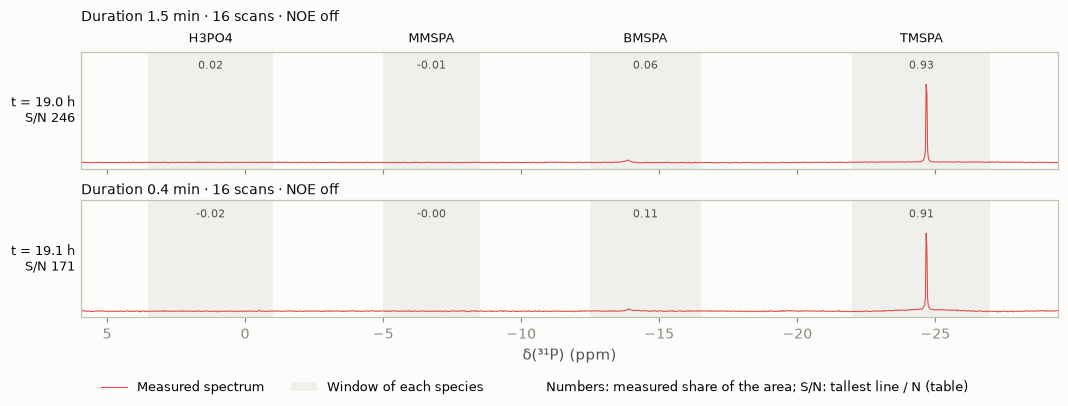

In [3]:
show_spectra(SHARES, DRAWN, '31P')

### 1.3 ¹³C

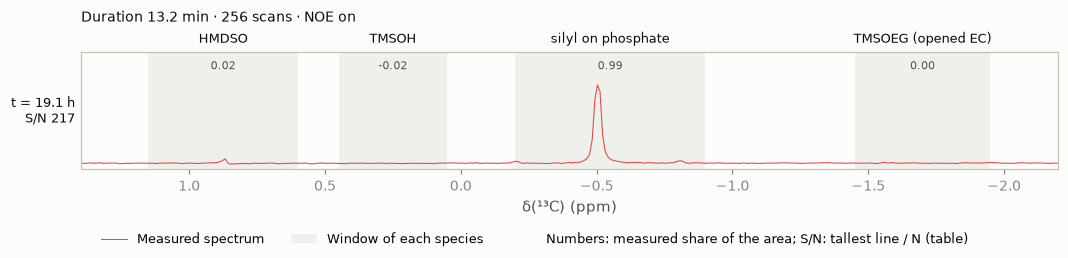

In [4]:
show_spectra(SHARES, DRAWN, '13C')

### 1.4 ²⁹Si

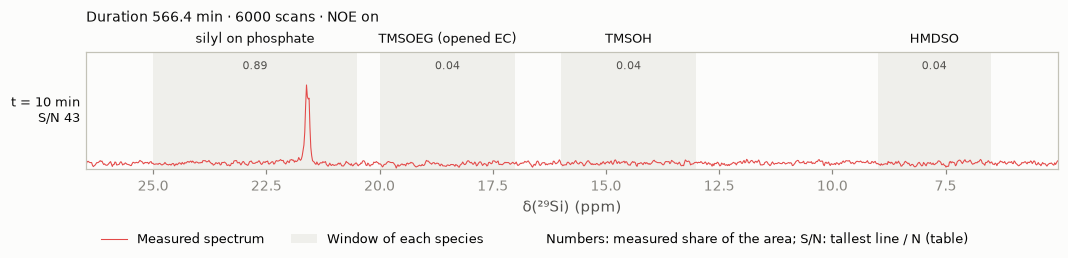

In [5]:
show_spectra(SHARES, DRAWN, '29Si')

### 1.5 ¹H

In [6]:
show_spectra(SHARES, DRAWN, '1H')

No ¹H spectrum of this tube: none recorded, or only noise.


---
## 2. TMSPa 5 % + H2O 2 %

- **The tube** (`2 % H2O` in the data files): 5 vol% TMSPA (149 mM) in EC/DEC with 2 vol% water (1 052 mM).
- **Its spectra:** 42 files over six days (22–28 Jun 2022): 12 ³¹P, 12 ¹³C, 12 ¹H, 6 ²⁹Si. Six rounds at room temperature (¹H, ³¹P, ¹³C, ²⁹Si) and six hot ones, at 30, 40, 50, 60, 70 and 80 °C (¹H, ¹³C, ³¹P).
- **The clock:** hours since TMSPA was added, at the 1 h reading (the first spectrum 1 h after mixing), with the heating as this project reads it (8 h at each temperature).
- **The model:** M1 after S5: the barriers of S3, nothing fitted to this tube (rev08 §2.5). The six ³¹P and six ¹³C at room temperature are scored by S5; the others are read here and compared.
- **The figures (2.2–2.5):** as in section 1; the first spectrum of the tube (the ¹H of 22 Jun) at t = 10 min. A hot spectrum shows its temperature in its title.


### 2.1 Every spectrum against the model

The columns and their definitions: §1.1.


In [7]:
SHARES_2, DRAWN_2 = tabulate_spectra('2 % H2O')
show_table(SHARES_2)

nucleus,S/N,H,N,scans,duration (min),s per scan,delay d1 (s),pulse (°),NOE,pulse program,T (°C),species,NMR (mM),model (mM),Δy (mM),σ noise (mM),σ baseline (mM),σ (mM),z (SD),fitted,note
³¹P,1,0.022,0.0163,16,1.5,5.7,5,45,off,carbon,22.5,TMSPA,-0.2,6.8,+7.0,1.43,3.95,3.48,+2.0,no,
³¹P,8,0.126,0.0163,16,1.5,5.7,5,45,off,carbon,22.5,BMSPA,7.1,31.9,+24.8,1.22,4.68,2.76,+9.0,no,
³¹P,47,0.772,0.0163,16,1.5,5.7,5,45,off,carbon,22.5,MMSPA,46.5,107.9,+61.4,1.10,1.44,3.48,+17.7,no,
³¹P,61,1.000,0.0163,16,1.5,5.7,5,45,off,carbon,22.5,H3PO4,99.3,2.8,-96.5,1.57,0.94,5.71,-16.9,no,
³¹P,1,0.010,0.0076,256,6.5,1.5,1,30,on,carbon,30.0,TMSPA,-1.3,0.0,+1.3,0.56,1.61,2.27,+0.6,no,
³¹P,18,0.139,0.0076,256,6.5,1.5,1,30,on,carbon,30.0,BMSPA,6.9,3.4,-3.4,0.48,1.72,2.33,-1.5,no,
³¹P,108,0.825,0.0076,256,6.5,1.5,1,30,on,carbon,30.0,MMSPA,50.6,112.7,+62.1,0.44,1.94,3.22,+19.3,no,
³¹P,131,1.000,0.0076,256,6.5,1.5,1,30,on,carbon,30.0,H3PO4,95.4,33.3,-62.1,0.59,0.29,4.81,-12.9,no,
³¹P,1,0.010,0.0114,256,6.6,1.5,1,30,on,carbon,40.0,TMSPA,-1.5,0.0,+1.5,0.61,2.29,2.80,+0.5,no,
³¹P,15,0.170,0.0114,256,6.6,1.5,1,30,on,carbon,40.0,BMSPA,7.6,2.1,-5.6,0.51,0.70,1.73,-3.2,no,


### 2.2 ³¹P

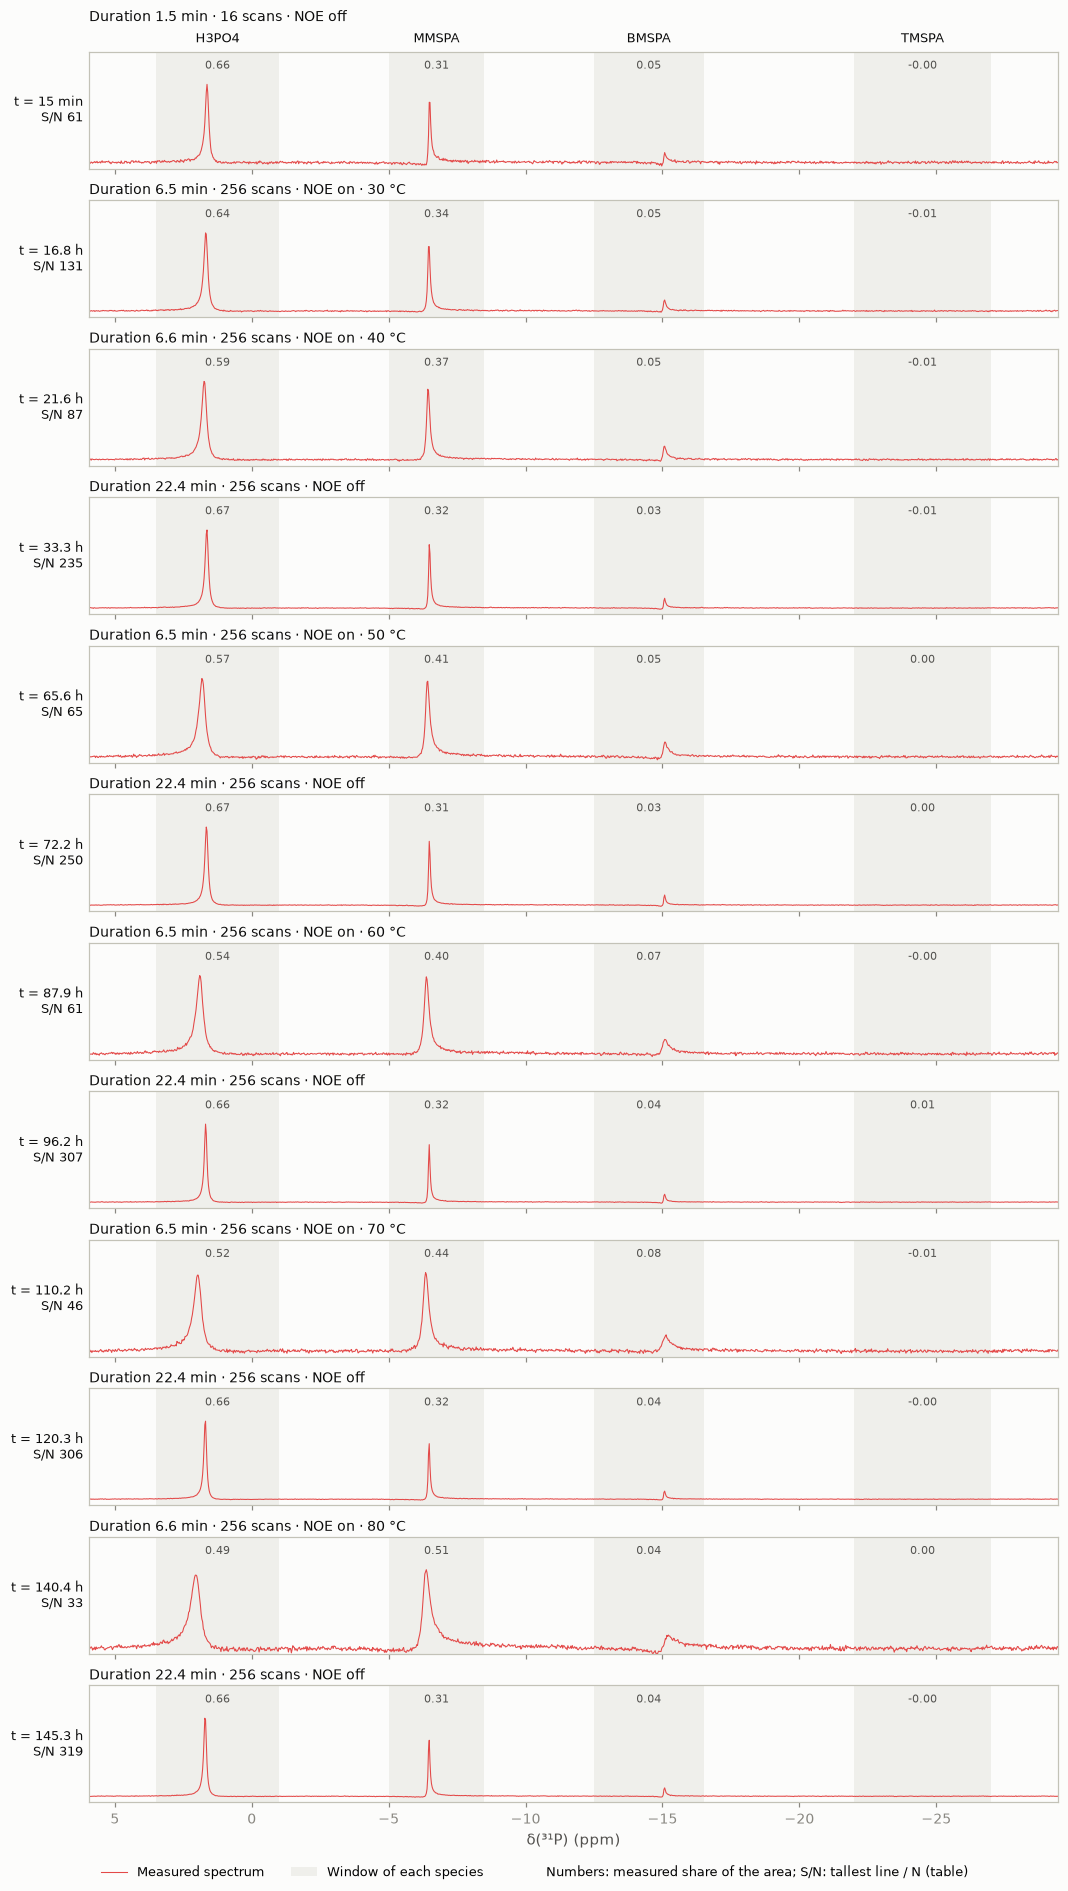

In [8]:
show_spectra(SHARES_2, DRAWN_2, '31P')

### 2.3 ¹³C

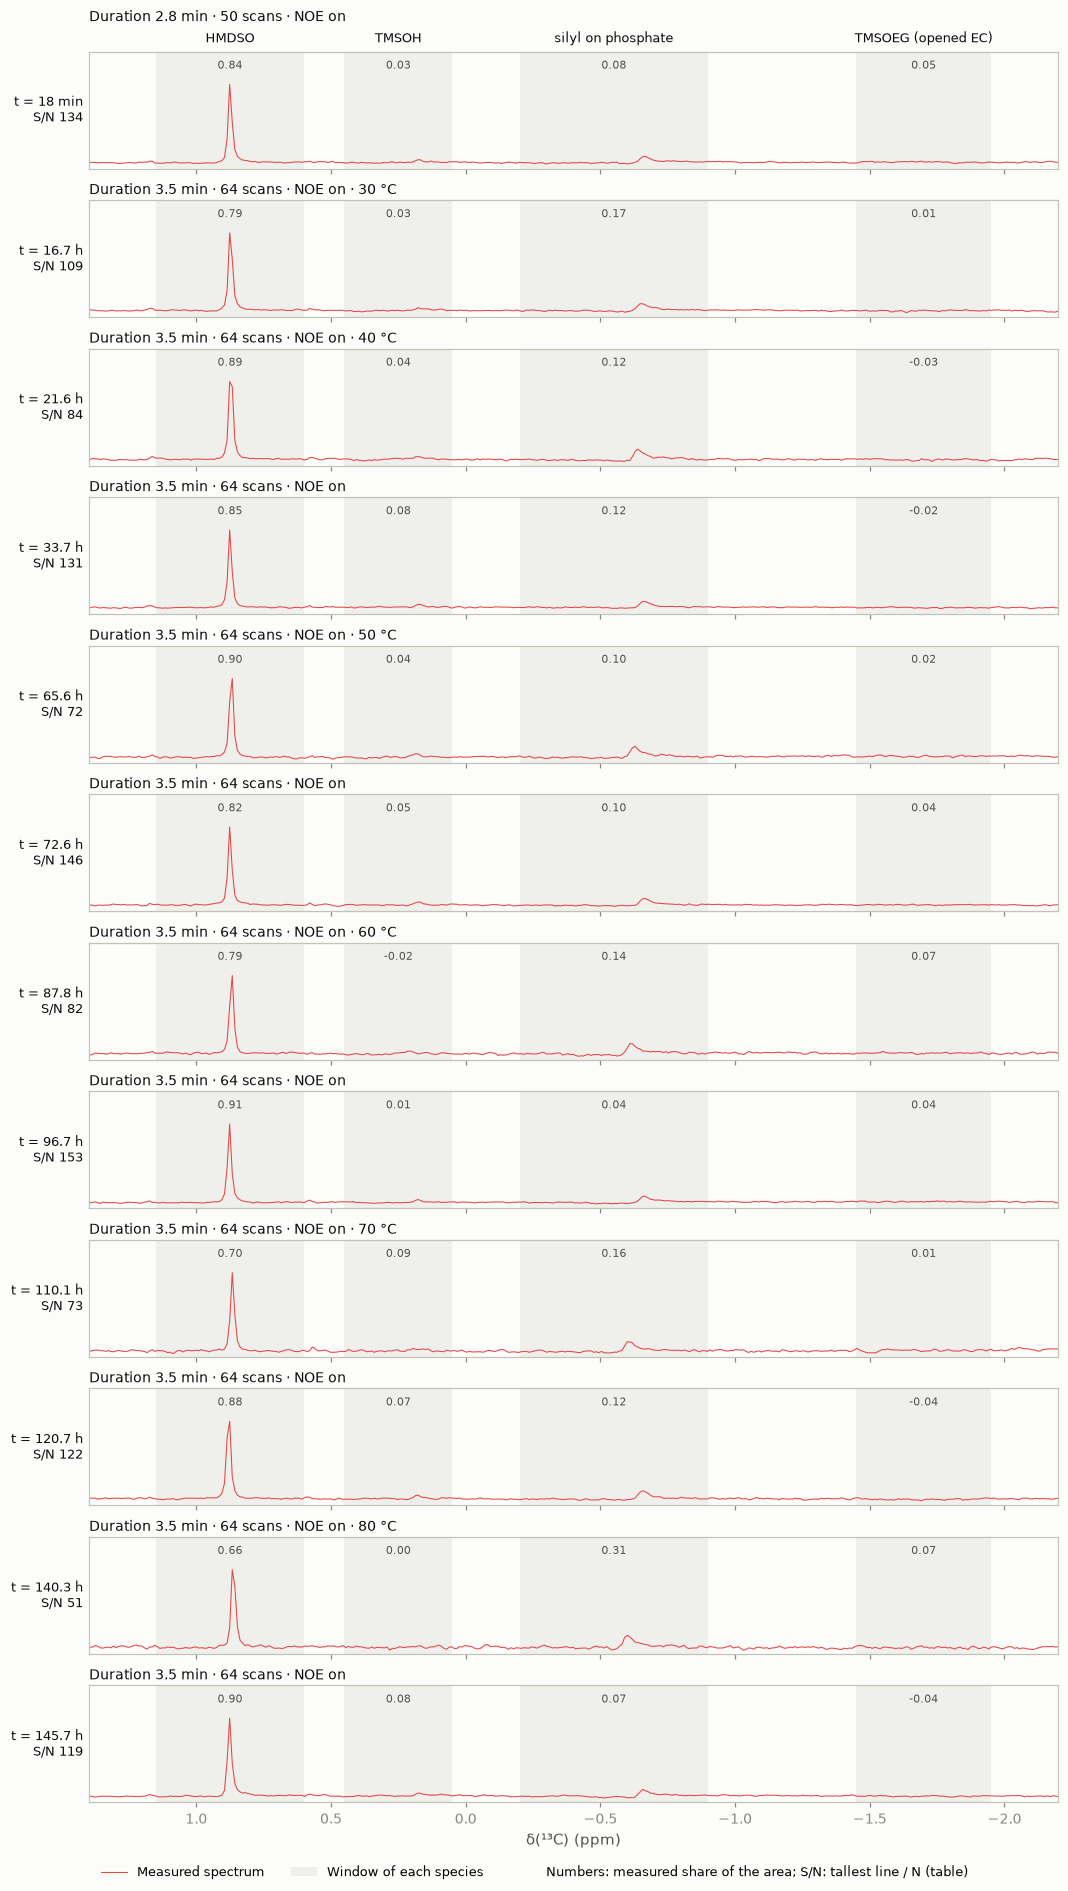

In [9]:
show_spectra(SHARES_2, DRAWN_2, '13C')

### 2.4 ²⁹Si

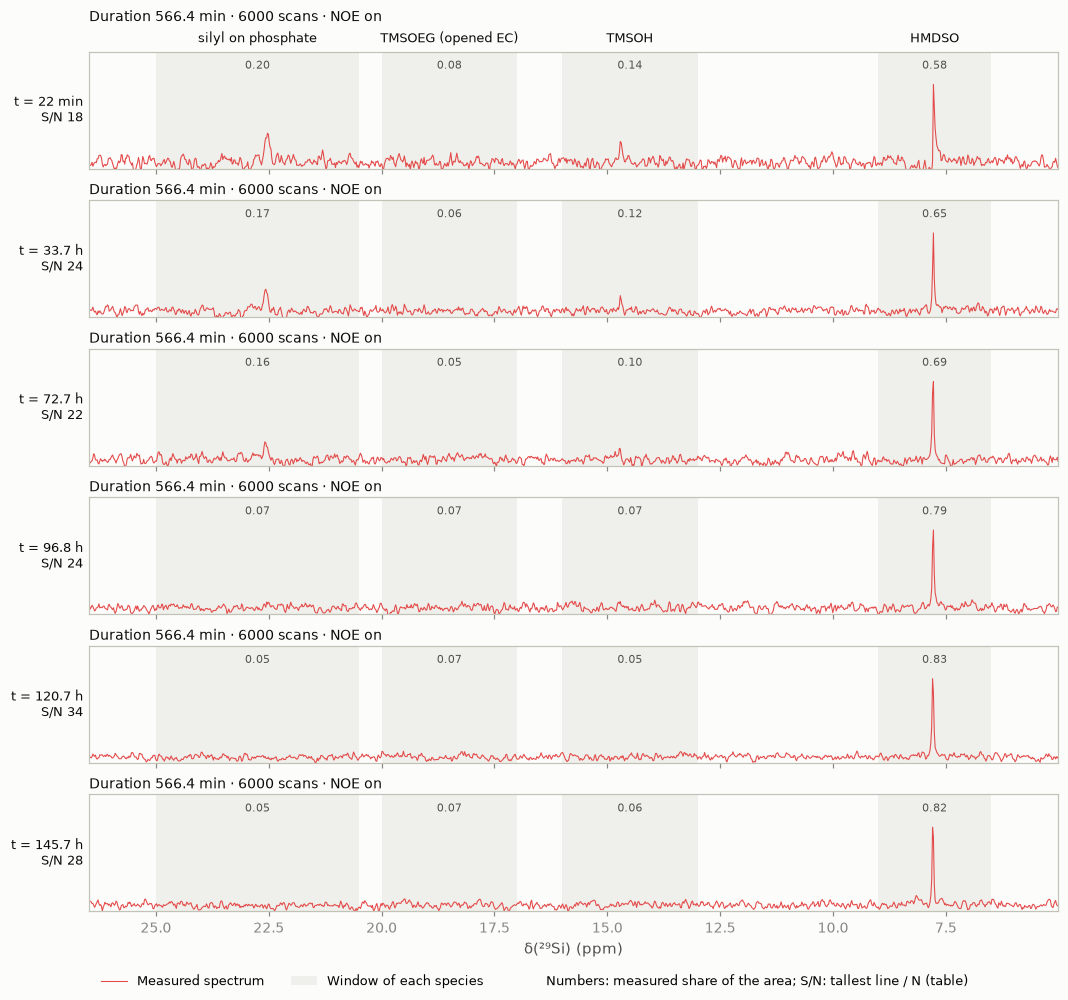

In [10]:
show_spectra(SHARES_2, DRAWN_2, '29Si')

### 2.5 ¹H

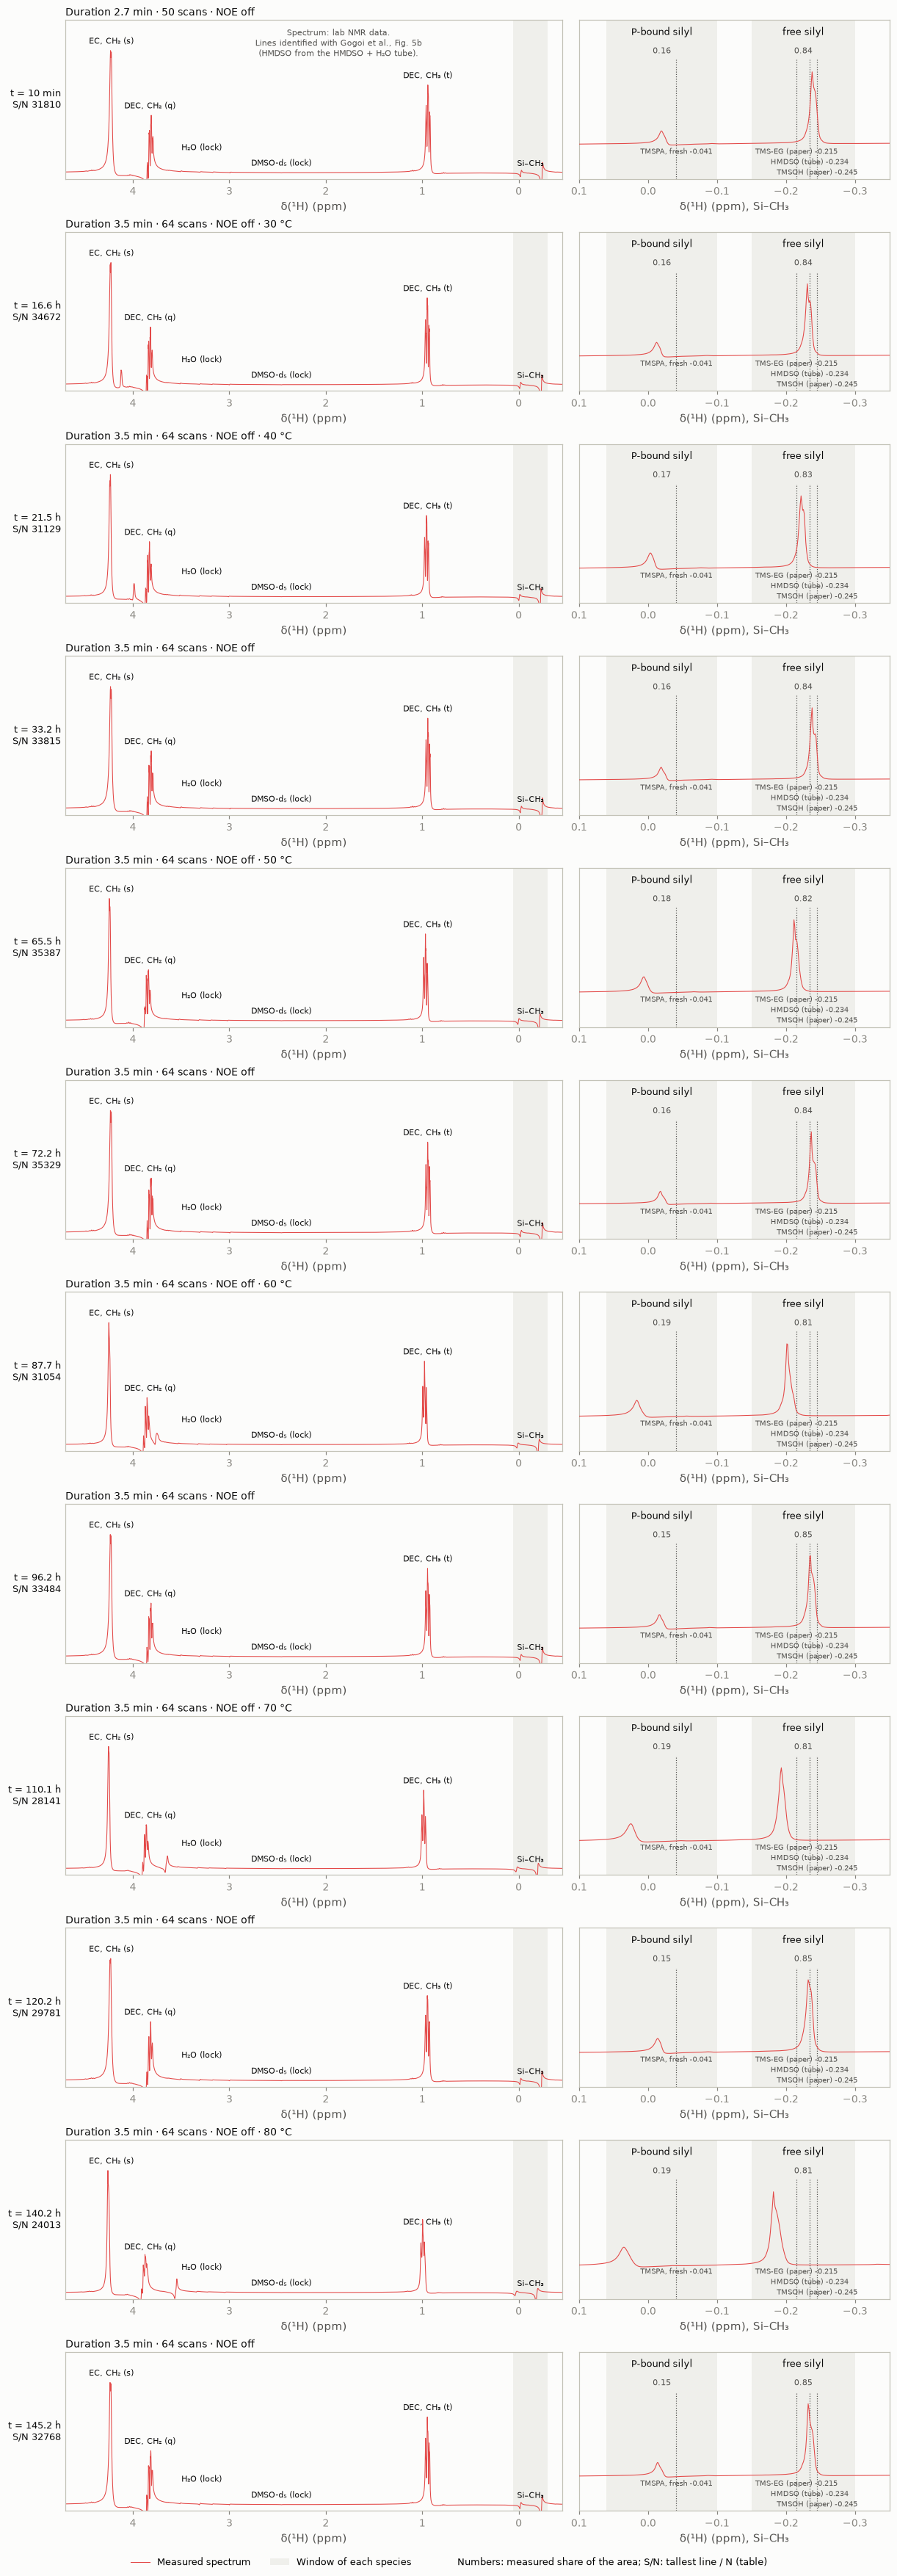

In [11]:
show_spectra(SHARES_2, DRAWN_2, '1H')